# How many FLOPs does one Walrus training round cost?

We try to derive an analytical formula to calculate the FLOPs required for one training pass. We will incorporate `model.hidden_dim`, `model.processor.space_mixing.mlp_dim`, and `model processor_blocks` as function inputs, as well as data-shape parameters (spatial resolution, time window, batch size, number of physical fields).

1. Initialise a small Walrus model through Hydra and run one real forward pass, so we observe the ground truth shapes.
2. Measure ground-truth FLOPs with PyTorch's `torch.utils.flop_counter.FlopCounterMode`, broken down per submodule.
3. For every submodule (encoder conv stages, spatial attention, temporal attention, channel mixing, decoder conv stages), derive the FLOP count from the module's source and check it against ground truth measurement.
   One of these checks turns up a real gap: `FlopCounterMode` silently
   under-counts one of the two attention calls because of which
   `scaled_dot_product_attention` backend CPU PyTorch dispatches to. We use
   the exact residual to prove this and patch the formula.
4. Combine the validated per-submodule formulas into one function covering the whole forward pass, then extend it to one full training round (forward + backward) via `6ND`-style FLOPs-per-token convention.
5. Apply the formula to Walrus's actual pretraining hyperparameters
   (`walrus/run_scripts/pretrain_example_distributed_walrus.sh`) and sweep
   `hidden_dim` / `processor_blocks` / `mlp_dim` to see how cost scales.

Throughout, one multiply-accumulate (`a*b + c`) is counted as 2 FLOPs, which also matches `torch.utils.flop_counter` and the convention behind the familiar "`2ND` forward pass" transformer FLOPs formula.

## Setup

We build the model like `walrus/train.py` and `tests/conftest.py` do. We will compose the Hydra config, instantiate a `MixedWellDataModule` against a tiny synthetic ("dummy") copy of a Well
dataset, and instantiate `IsotropicModel` from the composed config.

We start from `model=debug` (the config the test suite uses for fast end-to-end checks: `walrus/configs/model/debug.yaml`) but but with `model/processor/space_mixing=full_spatial_attention` rather than the default `axial_spatial_attention`, because axial spatial attention does not exist anfd we always ovveride it for `full_spatial_attention` in our scripts anyways.

In [1]:
import os
import pathlib as pl
import tempfile

os.chdir("/home/sshamsi/Projects/MHPC_Thesis")

import torch
from hydra import compose, initialize_config_dir
from hydra.utils import instantiate
from the_well.utils.dummy_data import write_dummy_data

from walrus.data.well_to_multi_transformer import ChannelsFirstWithTimeFormatter
from walrus.train import CONFIG_DIR, CONFIG_NAME

torch.manual_seed(0)

# A synthetic Well-format dataset, built like tests/conftest.py does
tmp_dir = pl.Path(tempfile.mkdtemp())
well_data_folder = tmp_dir / "well_data"
well_data_folder.mkdir()
for split in ["train", "valid", "test"]:
    split_dir = well_data_folder / "dummy" / "data" / split
    split_dir.mkdir(parents=True)
    write_dummy_data(split_dir / "data.hdf5")

print("Dummy dataset written to:", well_data_folder)

Dummy dataset written to: /tmp/tmp0knuj5lx/well_data


In [2]:
overrides = [
    "server=local",             # for my laptop
    "logger=none",              # No nned for debugging
    "trainer=debug",            # Fast end=to-end check
    "data=test",                # Dummy test YAML file
    "model=debug",              # Dummy model YAML file
    f"data.well_base_path={well_data_folder}",
    f"+data.module_parameters.well_dataset_info.dummy.path={well_data_folder / 'dummy'}",
    "data_workers=1",
    "name=flops_notebook",
    "automatic_setup=False",
    "model/processor/space_mixing=full_spatial_attention",  # Necessary override
]

with initialize_config_dir(config_dir=str(CONFIG_DIR), version_base=None):
    cfg = compose(config_name=CONFIG_NAME, overrides=overrides)

    datamodule = instantiate(
        cfg.data.module_parameters,
        world_size=1,
        rank=0,
        data_workers=cfg.data_workers,
        well_base_path=cfg.data.well_base_path,
        field_index_map_override={},
        transform=None,
    )
    field_to_index_map = datamodule.train_dataset.field_to_index_map
    n_states = max(field_to_index_map.values()) + 1

    model = instantiate(cfg.model, n_states=n_states)
    model.eval()  # dropout/drop-path off so shapes & FLOPs are deterministic

    formatter = ChannelsFirstWithTimeFormatter()
    batch = datamodule.train_dataset[0]
    inputs, y_ref = formatter.process_input(
        batch,
        causal_in_time=cfg.model.causal_in_time,
        predict_delta=cfg.trainer.prediction_type == "delta",
        train=True,
    )
    x, state_labels, bcs = inputs[0], inputs[1], inputs[2]

print("field_to_index_map:", field_to_index_map)
print("n_states (physical + BC/grid channels):", n_states)
print("model input x shape (T, B, C, H, W, D):", tuple(x.shape))

Failed to load acoustic_scattering_maze dataset


Failed to load acoustic_scattering_inclusions dataset


Failed to load acoustic_scattering_discontinuous dataset


Failed to load active_matter dataset


Failed to load convective_envelope_rsg dataset


...

Failed to load turbulent_radiative_layer_3D dataset


Failed to load viscoelastic_instability dataset


Failed to load viscoelastic_instability_v2 dataset


field_to_index_map: {'field_x': 0, 'field_y': 1, 'field_z': 2, 'constant_field': 3}
n_states (physical + BC/grid channels): 4
model input x shape (T, B, C, H, W, D): (2, 1, 4, 32, 32, 1)


/home/sshamsi/Projects/MHPC_Thesis/walrus/models/temporal_blocks/axial_time_attention.py:38: FutureWarning: `nn.init.kaiming_uniform` is now deprecated in favor of `nn.init.kaiming_uniform_`.
  init.kaiming_uniform(


## Look at the architecture

We have an encoder &rarr; processor &rarr; decoder stack

- `model.embed[dim_key]` is the encoder (`walrus/configs/model/encoder/spacebag_and_vstride_encoder.yaml`)
- `model.blocks` are `processor_blocks` copies of `SpaceTimeSplitBlock` (`walrus/models/spatiotemporal_blocks/space_time_split.py`) with:
  - `time_mixing`: `AxialTimeAttention`
  - `space_mixing`: `FullAttention` (where `mlp_dim` is relevant)
  - `channel_mixing`: `torch.nn.Identity` by default (0 FLOPs) (`walrus/models/shared_utils/mlps.py:MLP`)
- `model.debed[dim_key]` is the decoder, the transposed-conv mirror of the encoder (`AdaptiveDVstrideDecoder`, `walrus/models/decoders/vstride_decoder.py`).

We confirm this by hooking every stage of one real forward pass and printing the tensor shape after each one.

In [3]:
stage_shapes = {}


def record(name):
    def hook(module, inputs, output):
        out = output[0] if isinstance(output, tuple) else output
        stage_shapes[name] = tuple(out.shape)

    return hook


dim_key = "3"  # override_dimensionality: 3 in isotropic_model.yaml is always padded to 3D
model.embed[dim_key].register_forward_hook(record("1. encoder (embed)"))
block = model.blocks[0]
block.time_mixing.register_forward_hook(record("2. block[0].time_mixing"))
block.space_mixing.register_forward_hook(record("3. block[0].space_mixing"))
block.register_forward_hook(record("4. block[0] (full block output)"))
model.debed[dim_key].register_forward_hook(record("5. decoder (debed)"))

with torch.no_grad():
    y_pred = model(x, state_labels, bcs.tolist(), metadata=batch["metadata"])

stage_shapes["0. model input"] = tuple(x.shape)
stage_shapes["6. model output"] = tuple(y_pred.shape)

for name in sorted(stage_shapes):
    print(f"{name:35s} (T, B, C, H, W, D) = {stage_shapes[name]}")

0. model input                      (T, B, C, H, W, D) = (2, 1, 4, 32, 32, 1)
1. encoder (embed)                  (T, B, C, H, W, D) = (2, 1, 8, 32, 32, 1)
2. block[0].time_mixing             (T, B, C, H, W, D) = (2, 1, 8, 32, 32, 1)
3. block[0].space_mixing            (T, B, C, H, W, D) = (2, 8, 32, 32, 1)
4. block[0] (full block output)     (T, B, C, H, W, D) = (2, 1, 8, 32, 32, 1)
5. decoder (debed)                  (T, B, C, H, W, D) = (1, 1, 4, 42, 42, 1)
6. model output                     (T, B, C, H, W, D) = (1, 1, 4, 32, 32, 1)


- The encoder maps raw `n_states`-channel field grid to `hidden_dim` channels
- `time_mixing` and `space_mixing` preserve shape
- The decoder maps back down to `n_states` channels.
- `n_spatial_dims` here is 2 (this dummy dataset is 2D, so `D == 1` throughout), but because `override_dimensionality: 3` in `isotropic_model.yaml`, every tensor is still padded to a 3-tuple `(H, W, D)`

## Measure ground-truth FLOPs

PyTorch has an operator-level FLOP counter, [`torch.utils.flop_counter.FlopCounterMode`](https://pytorch.org/docs/stable/torch.compiler_flop_counter.html), which intercepts every op during a forward pass. For the ops it has a formula for matmuls, convs, a handful of attention kernels, and then it adds up FLOPs per `nn.Module`.

We'll use this as ground truth to check our hand-derived formulas.

In [4]:
from torch.utils.flop_counter import FlopCounterMode

with torch.no_grad(), FlopCounterMode(display=False) as fc:
    _ = model(x, state_labels, bcs.tolist(), metadata=batch["metadata"])

measured = {mod: sum(counts.values()) for mod, counts in fc.flop_counts.items()}
total_measured = fc.get_total_flops()

print(f"Total measured forward-pass FLOPs: {total_measured:,}\n")
for mod in sorted(measured):
    if mod in ("Global", "IsotropicModel"):
        continue
    print(f"{mod:55s} {measured[mod]:>14,}")

Total measured forward-pass FLOPs: 696,696,832

IsotropicModel.blocks.0                                      3,801,088
IsotropicModel.blocks.0.space_mixing                         2,621,440
IsotropicModel.blocks.0.space_mixing.attn_out                  262,144
IsotropicModel.blocks.0.space_mixing.ff_out                    524,288
IsotropicModel.blocks.0.space_mixing.fused_ff_qkv            1,835,008
IsotropicModel.blocks.0.time_mixing                          1,179,648
IsotropicModel.blocks.0.time_mixing.input_head                 786,432
IsotropicModel.blocks.0.time_mixing.output_head                262,144
IsotropicModel.debed.3                                     170,754,048
IsotropicModel.embed.3                                     522,141,696


`IsotropicModel` = `embed.3` + `blocks.0` + `debed.3`.
`blocks.0` = `space_mixing` + `time_mixing` (`channel_mixing` is `Identity`, contributing exactly 0).

We'll now derive each of these four numbers (`embed.3`, `space_mixing`, `time_mixing`, `debed.3`) from the module source, and check the arithmetic matches to the FLOP.

## Encoder & decoder

`SpaceBagAdaptiveDVstrideEncoder` (`walrus/models/encoders/vstride_encoder.py`) runs two conv layers, `proj1` then `proj2`.
The conv kernel size is fixed at construction time (`base_kernel1`/`base_kernel2`, taken from `base_kernel_size3d` in `walrus/configs/model/encoder/spacebag_and_vstride_encoder.yaml` is `(8, 8, 8)` then `(4, 4, 4)` by default), but the stride is chosen dynamically per batch (`choose_kernel_size_deterministic` in `walrus/models/shared_utils/flexi_utils.py`) to hit a target internal token count for whatever resolution the current dataset happens to be at.

Additionally, `AdaptiveDVstrideEncoder.adaptive_conv` collapses the kernel to size 1 along any axis whose input is already singleton (`walrus/models/encoders/vstride_encoder.py:244-248`).

A simple, adaptive-collapsed, strided conv, the output size from a convolution is:

$$
O = \left[ \frac{I - k + 2p}{s} \right] + 1
$$

Where $O$ is the output size, $I$ is the input size or width, $k$ is the kernel size, $s$ is the stride, and $p$ is the padding size on each side. But there is no padding in our case.

And the total FLOPs is the (number of output positions) × (number of output channels) × (kernel size × number of input channes) × 2


$$\text{FLOPs} = 2 \cdot N_{\text{batch}} \cdot \prod_i O_i \cdot \Big(\prod_i k_i\Big) \cdot C_{in} \cdot C_{out}$$

where $O_i$ is the output size along spatial axis $i$ from the strided-conv size formula

$$
O_i = \left[ \frac{I_i - k_i}{s_i} \right] + 1
$$
with $k_i = 1$ on singleton axes. $N_{\text{batch}} = T \cdot B$ because the encoder flattens time into the batch dimension. The decoder mirrors this exactly.

In [5]:
import math
from typing import Sequence


def conv_out_size(in_size: int, kernel: int, stride: int) -> int:
    '''Strided-conv output size along one axis (no padding; Walrus's learned_pad
    path always uses padding=0 and pads the input beforehand instead).'''
    if in_size == 1:
        return 1  # kernel collapses to 1 on singleton axes (adaptive_conv)
    return (in_size - kernel) // stride + 1


def conv_stage_flops(
    in_shape: Sequence[int],
    kernel: Sequence[int],
    stride: Sequence[int],
    c_in: int,
    c_out: int,
    batch: int,
    transposed: bool = False,
) -> int:
    '''FLOPs for one Walrus adaptive strided (or transposed) conv stage.

    `in_shape` is the spatial shape entering this stage. For a forward conv we
    count per OUTPUT position; for a transposed conv we count per INPUT
    position (algebraically the same multiply-add count either way).
    '''
    kernel = [1 if s == 1 else k for k, s in zip(kernel, in_shape)]
    if transposed:
        n_positions = math.prod(in_shape)
    else:
        out_shape = [conv_out_size(s, k, st) for s, k, st in zip(in_shape, kernel, stride)]
        n_positions = math.prod(out_shape)
    kernel_volume = math.prod(kernel)
    return 2 * batch * n_positions * kernel_volume * c_in * c_out

Now apply this to the actual encoder. We need: the padded shape entering
`proj1`, the shape entering `proj2` (`proj1`'s output), the two fixed kernels,
the chosen stride (`random_kernel`, i.e. `((1,1),(1,1),(1,1))` at this
resolution &mdash; the dummy data's 32&times;32 grid already matches the
target internal token count, so both stages use stride 1 here), and the
channel counts. We trace these directly off the live encoder/decoder modules
rather than re-deriving Walrus's padding/stride-selection logic (a data-pipeline
concern orthogonal to the architecture), so the check below is exact.

In [6]:
encoder = model.embed[dim_key]
decoder = model.debed[dim_key]

traced = {}


def trace_encoder(orig):
    def wrapped(x_in, field_indices, bcs=None, metadata=None, **kwargs):
        traced["enc_in_shape"] = tuple(x_in.shape)
        traced["enc_field_indices"] = field_indices
        traced["enc_stride"] = kwargs["random_kernel"]
        out, kw = orig(x_in, field_indices, bcs, metadata, **kwargs)
        traced["enc_out_shape"] = tuple(out.shape)
        return out, kw

    return wrapped


def trace_decoder(orig):
    def wrapped(x_in, state_labels_, bcs=None, stage_info=None, metadata=None):
        traced["dec_in_shape"] = tuple(x_in.shape)
        out = orig(x_in, state_labels_, bcs, stage_info, metadata)
        traced["dec_out_shape"] = tuple(out.shape)
        return out

    return wrapped


encoder.forward = trace_encoder(encoder.forward)
decoder.forward = trace_decoder(decoder.forward)

with torch.no_grad():
    _ = model(x, state_labels, bcs.tolist(), metadata=batch["metadata"])

for k, v in traced.items():
    print(f"{k:18s} {v}")

enc_in_shape       (2, 1, 7, 42, 42, 1)
enc_field_indices  tensor([0, 1, 2, 3, 2, 0, 1])
enc_stride         ((1, 1), (1, 1), (1, 1))
enc_out_shape      (2, 1, 8, 32, 32, 1)
dec_in_shape       (1, 1, 8, 32, 32, 1)
dec_out_shape      (1, 1, 4, 42, 42, 1)


In [7]:
# --- Encoder ---
# proj1: C_in = len(field_indices) (n_states + 3 "space bag" grid/BC channels
# reused via index repetition), C_out = intermediate_dim.
T_enc, B_enc, C_in_enc, *spatial_in_enc = traced["enc_in_shape"]
c_in1 = len(traced["enc_field_indices"])
c_inner = cfg.model.intermediate_dim
c_hidden = cfg.model.hidden_dim
stride = [s[0] for s in traced["enc_stride"]]  # stride1 per axis (embed_kernel[i][0])
stride2 = [s[1] for s in traced["enc_stride"]]  # stride2 per axis (embed_kernel[i][1])

k1, k2 = encoder.base_kernel1, encoder.base_kernel2
flops_enc1 = conv_stage_flops(spatial_in_enc, k1, stride, c_in1, c_inner, batch=T_enc * B_enc)

spatial_mid_enc = [conv_out_size(s, (1 if s == 1 else k), st) for s, k, st in zip(spatial_in_enc, k1, stride)]
flops_enc2 = conv_stage_flops(spatial_mid_enc, k2, stride2, c_inner, c_hidden, batch=T_enc * B_enc)

flops_encoder = flops_enc1 + flops_enc2
print(f"encoder proj1 (kernel={k1}, stride={stride}): {flops_enc1:>14,} FLOPs")
print(f"encoder proj2 (kernel={k2}, stride={stride2}): {flops_enc2:>14,} FLOPs")
print(f"encoder total:                                        {flops_encoder:>14,} FLOPs")
print(f"measured 'embed.{dim_key}':                                {measured[f'IsotropicModel.embed.{dim_key}']:>14,} FLOPs")
assert flops_encoder == measured[f"IsotropicModel.embed.{dim_key}"]
print("\n MATCH")

encoder proj1 (kernel=(8, 8, 8), stride=[1, 1, 1]):    421,478,400 FLOPs
encoder proj2 (kernel=(4, 4, 4), stride=[1, 1, 1]):    100,663,296 FLOPs
encoder total:                                           522,141,696 FLOPs
measured 'embed.3':                                   522,141,696 FLOPs

 MATCH


In [8]:
# --- Decoder --- (transposed-conv mirror; proj1 uses base_kernel2-sized kernel
# (4,4,4) first, proj2 uses base_kernel1-sized kernel (8,8,8) second - see
# AdaptiveDVstrideDecoder.__init__)
T_dec, B_dec, C_in_dec, *spatial_in_dec = traced["dec_in_shape"]
c_out_dec = n_states

dk1, dk2 = decoder.base_kernel1, decoder.base_kernel2  # (4,4,4), (8,8,8)
dstride1 = [s[0] for s in traced["enc_stride"]]  # debed strides == embed strides here (all 1s)
dstride2 = [s[1] for s in traced["enc_stride"]]

flops_dec1 = conv_stage_flops(
    spatial_in_dec, dk1, dstride1, c_hidden, c_inner, batch=T_dec * B_dec, transposed=True
)
# ConvTranspose output size: (in - 1) * stride + kernel  (padding=0, dim=1 axes fixed at size 1)
spatial_mid_dec = [
    1 if s == 1 else (s - 1) * st + k for s, k, st in zip(spatial_in_dec, dk1, dstride1)
]
flops_dec2 = conv_stage_flops(
    spatial_mid_dec, dk2, dstride2, c_inner, c_out_dec, batch=T_dec * B_dec, transposed=True
)

flops_decoder = flops_dec1 + flops_dec2
print(f"decoder proj1 (kernel={dk1}, stride={dstride1}): {flops_dec1:>14,} FLOPs")
print(f"decoder proj2 (kernel={dk2}, stride={dstride2}): {flops_dec2:>14,} FLOPs")
print(f"decoder total:                                        {flops_decoder:>14,} FLOPs")
print(f"measured 'debed.{dim_key}':                                {measured[f'IsotropicModel.debed.{dim_key}']:>14,} FLOPs")
assert flops_decoder == measured[f"IsotropicModel.debed.{dim_key}"]
print("\n MATCH")

decoder proj1 (kernel=(4, 4, 4), stride=[1, 1, 1]):     50,331,648 FLOPs
decoder proj2 (kernel=(8, 8, 8), stride=[1, 1, 1]):    120,422,400 FLOPs
decoder total:                                           170,754,048 FLOPs
measured 'debed.3':                                   170,754,048 FLOPs

 MATCH


`model.projection_dim` only sizes a small per-channel padding-token buffer used by the patch jitterer (`walrus/models/isotropic_model.py`, `self.patch_jitterer`), not a matmul/conv, so it doesn't affect FLOPs.

`model.intermediate_dim` (the conv "neck" width), `model.hidden_dim` do affect FLOPs

## Space mixing

`FullAttention` (`walrus/models/spatial_blocks/full_attention.py`) runs self-attention over the spatial tokens ($N_{space} = H \cdot W \cdot D$), independently for each of the $T \cdot B$ time-steps&times;batch elements. `FullAttention.forward` does the following:

1. `fused_ff_qkv` is one layer `nn.Linear(hidden_dim, mlp_dim + 3*hidden_dim)` that jointly produces the channel-mixing-MLP pre-activation (width `mlp_dim`, for a `SwiGLU`) and `Q, K, V` (each width `hidden_dim`) in one matmul.
2. `F.scaled_dot_product_attention(q, k, v)` over `N_space` tokens, split across `num_heads` heads of size `hidden_dim / num_heads`.
3. `attn_out`: `nn.Linear(hidden_dim, hidden_dim, bias=False)` projecting the attention output back down.
4. `ff_out`: `nn.Linear(mlp_dim // 2, hidden_dim)` (`SwiGLU` first halves `mlp_dim`)

FLOPs for the three linear layers are the standard $2 \cdot N \cdot d_{in} \cdot d_{out}$


**Attention:**

For each token, attention builds a query vector. For every token (including itself) it also has a key and a value vector. The token compares its query against every key (that's $QK^\top$ or one dot product per pair of tokens). These comparison scores are turned to weights with softmax, and then takes a weighted sum of everyone's values using those weights.

For $N$ tokens, there are $N^2$ (query, key) pairs. Computing a dot product over `d_head` means `2 x d_head` FLOPs per pair. That's $2 \times N^2 \times d\_head$ FLOPs.

For every one of the $N$ output tokens, we combine $N$ value-vectors of length `d_head`, weighted by the $N$. We get the same $2 \times N^2 \times d\_head$ FLOPs.

Thus, attention for one head plus softmax costs $2 \times (2 \times N^2 \times d\_head)$


**Multiple Heads:**

Each token's vector is split into into `num_heads` smaller chunks of size `d_head = hidden_dim / num_heads`, so the FLOPs value for one attention head gets multiplied by `num_heads`.

That is, `num_heads × 2 × (2 · N² · d_head) = 4 · N² · (d_head · num_heads)`

But `d_head x num_heads = hidden_dim` so it simplifies.

$$\text{FLOPs}_{\text{attn}} = \underbrace{2}_{QK^\top,\,AV} \cdot \underbrace{2 \cdot N_{space}^2 \cdot d_{head}}_{\text{per head}} \cdot \text{num\_heads} \cdot (T{\cdot}B) = 4 \cdot (T{\cdot}B) \cdot N_{space}^2 \cdot \text{hidden\_dim}$$

In [9]:
def space_mixing_flops(hidden_dim, mlp_dim, n_space, t_times_b):
    '''FLOPs for one FullAttention (spatial) block, broken down by submodule.'''
    fused_ff_qkv = 2 * t_times_b * n_space * hidden_dim * (mlp_dim + 3 * hidden_dim)
    attn = 4 * t_times_b * (n_space ** 2) * hidden_dim
    attn_out = 2 * t_times_b * n_space * hidden_dim * hidden_dim
    ff_out = 2 * t_times_b * n_space * (mlp_dim // 2) * hidden_dim
    return {
        "fused_ff_qkv": fused_ff_qkv,
        "attention": attn,
        "attn_out": attn_out,
        "ff_out": ff_out,
    }


space_block = model.blocks[0].space_mixing
_, _, H, W, D = stage_shapes["3. block[0].space_mixing"]
n_space = H * W * D
t_times_b = stage_shapes["2. block[0].time_mixing"][0] * stage_shapes["2. block[0].time_mixing"][1]

breakdown = space_mixing_flops(space_block.hidden_dim if hasattr(space_block, "hidden_dim") else cfg.model.hidden_dim,
                               space_block.mlp_dim, n_space, t_times_b)
hand_total = sum(breakdown.values())

print("hand-derived breakdown:")
for k, v in breakdown.items():
    print(f"  {k:14s} {v:>14,}")
print(f"  {'TOTAL':14s} {hand_total:>14,}\n")

measured_space = measured["IsotropicModel.blocks.0.space_mixing"]
measured_children_sum = sum(
    v for k, v in measured.items() if k.startswith("IsotropicModel.blocks.0.space_mixing.")
)
print(f"measured space_mixing total (incl. attention op): {measured_space:>14,}")
print(f"measured sum of space_mixing's *named children*:   {measured_children_sum:>14,}")
print(f"discrepancy (unattributed to any child module):     {measured_space - measured_children_sum:>14,}")

hand-derived breakdown:
  fused_ff_qkv        1,835,008
  attention          67,108,864
  attn_out              262,144
  ff_out                524,288
  TOTAL              69,730,304

measured space_mixing total (incl. attention op):      2,621,440
measured sum of space_mixing's *named children*:        2,621,440
discrepancy (unattributed to any child module):                  0


`FlopCounterMode`'s total for `space_mixing` equals just its three linear children, no attention added. Why?

In [10]:
print(f"hand-derived attention-op FLOPs:  {breakdown['attention']:>14,}")
print(f"measured space_mixing total:      {measured_space:>14,}")
print(f"hand-derived total (incl. attn):  {hand_total:>14,}")
print(f"gap vs. measured:                 {hand_total - measured_space:>14,}")
print(f"...which equals the attention-op term exactly: {hand_total - measured_space == breakdown['attention']}")

hand-derived attention-op FLOPs:      67,108,864
measured space_mixing total:           2,621,440
hand-derived total (incl. attn):      69,730,304
gap vs. measured:                     67,108,864
...which equals the attention-op term exactly: True


`FlopCounterMode` only has registered FLOP formulas for a handful of fused attention kernels (`aten._scaled_dot_product_flash_attention`, `..._efficient_attention`, `..._cudnn_attention`, and their backward passes. See `torch.utils.flop_counter.flop_registry`).

`FullAttention.forward` calls `F.scaled_dot_product_attention(q, k, v)` with no mask and no explicit backend, which on this CPU-only PyTorch build dispatches to `aten._scaled_dot_product_flash_attention_for_cpu` which is a different, unregistered op name, so its FLOPs are silently recorded as zero.

The next section does not have this issue though. `AxialTimeAttention` calls `scaled_dot_product_attention` with an additive bias mask, which forces a different (registered) backend, so its attention FLOPs do show up in `FlopCounterMode`.

## Time mixing

`AxialTimeAttention` (`walrus/models/temporal_blocks/axial_time_attention.py`) runs self-attention over time ($T$ tokens), independently for every spatial location, batched over $B \cdot N_{space}$.

The forward pass is:

1. `input_head` is a `nn.Conv3d(hidden_dim, 3*hidden_dim, kernel_size=1)` a per-position linear layer producing $Q, K, V$.
2. Attention over $T$ tokens, per head, batched over $B \cdot N_{space}$ positions.
3. **`output_head`**: `nn.Conv3d(hidden_dim, hidden_dim, kernel_size=1)`.

$$\text{FLOPs}_{\text{attn}} = 4 \cdot B \cdot N_{space} \cdot T^2 \cdot \text{hidden\_dim}$$

In [11]:
def time_mixing_flops(hidden_dim, t, b_times_n_space):
    '''FLOPs for one AxialTimeAttention (temporal) block, broken down by submodule.'''
    input_head = 2 * (t * b_times_n_space) * hidden_dim * (3 * hidden_dim)
    attn = 4 * b_times_n_space * (t ** 2) * hidden_dim
    output_head = 2 * (t * b_times_n_space) * hidden_dim * hidden_dim
    return {"input_head": input_head, "attention": attn, "output_head": output_head}


T_blk, B_blk = stage_shapes["2. block[0].time_mixing"][:2]
breakdown_t = time_mixing_flops(cfg.model.hidden_dim, T_blk, B_blk * n_space)
hand_total_t = sum(breakdown_t.values())

print("hand-derived breakdown:")
for k, v in breakdown_t.items():
    print(f"  {k:14s} {v:>14,}")
print(f"  {'TOTAL':14s} {hand_total_t:>14,}\n")

measured_time = measured["IsotropicModel.blocks.0.time_mixing"]
print(f"measured time_mixing total: {measured_time:>14,}")
assert hand_total_t == measured_time
print("\n MATCH")

hand-derived breakdown:
  input_head            786,432
  attention             131,072
  output_head           262,144
  TOTAL               1,179,648

measured time_mixing total:      1,179,648

 MATCH


## Channel mixing

`walrus/configs/model/processor/space_time_split.yaml` defaults `channel_mixing` to `torch.nn.Identity` 0 FLOPs, confirmed above (`blocks.0` total = `space_mixing` + `time_mixing` exactly, nothing left over).

The alternative, `walrus/configs/model/processor/channel_mixing/generic_mlp.yaml`, swaps in `walrus.models.shared_utils.mlps.MLP` (a plain 2-layer GELU MLP, default `exp_factor=4.0`, i.e. its own inner width is `4*hidden_dim` by default, independent of the space-mixing `mlp_dim`), applied per-token over every $(T,B,H,W,D)$ position:

In [12]:
def channel_mixing_flops(hidden_dim, channel_mlp_dim, n_tokens):
    '''0 if Identity (the default); else a 2-layer MLP applied per token.'''
    if channel_mlp_dim is None:
        return 0
    fc1 = 2 * n_tokens * hidden_dim * channel_mlp_dim
    fc2 = 2 * n_tokens * channel_mlp_dim * hidden_dim
    return fc1 + fc2


# Default config: Identity -> 0, matching the exact block-level check below.
measured_block0 = measured["IsotropicModel.blocks.0"]
print(f"measured space_mixing + time_mixing: {breakdown_t and (measured_space + measured_time):>14,}")
print(f"measured blocks.0 (whole block):     {measured_block0:>14,}")
assert measured_block0 == measured_space + measured_time
print("\n MATCH - channel_mixing (Identity) contributes exactly 0")

measured space_mixing + time_mixing:      3,801,088
measured blocks.0 (whole block):          3,801,088

 MATCH - channel_mixing (Identity) contributes exactly 0


## THe whole forward-pass formula

In [13]:
from dataclasses import dataclass


@dataclass
class WalrusFlopConfig:
    hidden_dim: int
    mlp_dim: int  # model.processor.space_mixing.mlp_dim (None -> 4*hidden_dim, same as FullAttention's default)
    processor_blocks: int
    intermediate_dim: int  # model.intermediate_dim
    n_states: int  # physical + BC/grid fields, from field_to_index_map
    n_states_extra: int = 3  # SpaceBag's extra grid/BC channels appended before proj1
    channel_mlp_dim: "int | None" = None  # None -> Identity (default); else generic_mlp width
    encoder_kernel1: tuple = (8, 8, 8)
    encoder_kernel2: tuple = (4, 4, 4)
    causal_in_time: bool = False

    def __post_init__(self):
        if self.mlp_dim is None:
            self.mlp_dim = 4 * self.hidden_dim


def walrus_forward_flops(
    cfgw: WalrusFlopConfig,
    encoder_in_shape,  # padded (H, W, D) entering the encoder's first conv
    encoder_mid_shape,  # (H, W, D) between the encoder's two conv stages
    internal_shape,  # (H, W, D) = the processor's token grid (encoder's final output)
    encoder_stride1,
    encoder_stride2,
    T: int,
    B: int,
):
    '''Total forward-pass FLOPs for IsotropicModel, as validated in sections 3-6.

    `T` is the number of input time steps fed to the processor (n_steps_input);
    the decoder only re-expands the LAST time step unless causal_in_time=True.
    '''
    c_in1 = cfgw.n_states + cfgw.n_states_extra

    enc1 = conv_stage_flops(encoder_in_shape, cfgw.encoder_kernel1, encoder_stride1,
                             c_in1, cfgw.intermediate_dim, batch=T * B)
    enc2 = conv_stage_flops(encoder_mid_shape, cfgw.encoder_kernel2, encoder_stride2,
                             cfgw.intermediate_dim, cfgw.hidden_dim, batch=T * B)
    encoder_flops = enc1 + enc2

    n_space = math.prod(internal_shape)
    space = space_mixing_flops(cfgw.hidden_dim, cfgw.mlp_dim, n_space, T * B)
    time_ = time_mixing_flops(cfgw.hidden_dim, T, B * n_space)
    channel = channel_mixing_flops(cfgw.hidden_dim, cfgw.channel_mlp_dim, T * B * n_space)
    per_block = sum(space.values()) + sum(time_.values()) + channel
    processor_flops = cfgw.processor_blocks * per_block

    T_out = T if cfgw.causal_in_time else 1
    dec1 = conv_stage_flops(internal_shape, cfgw.encoder_kernel2, encoder_stride2,
                             cfgw.hidden_dim, cfgw.intermediate_dim, batch=T_out * B, transposed=True)
    dec_mid_shape = [
        1 if s == 1 else (s - 1) * st + k
        for s, k, st in zip(internal_shape, cfgw.encoder_kernel2, encoder_stride2)
    ]
    dec2 = conv_stage_flops(dec_mid_shape, cfgw.encoder_kernel1, encoder_stride1,
                             cfgw.intermediate_dim, cfgw.n_states, batch=T_out * B, transposed=True)
    decoder_flops = dec1 + dec2

    return {
        "encoder": encoder_flops,
        "processor": processor_flops,
        "decoder": decoder_flops,
        "total": encoder_flops + processor_flops + decoder_flops,
    }

In [14]:
# Validate the assembled formula against this notebook's live debug model.
cfgw_debug = WalrusFlopConfig(
    hidden_dim=cfg.model.hidden_dim,
    mlp_dim=space_block.mlp_dim,
    processor_blocks=len(model.blocks),
    intermediate_dim=cfg.model.intermediate_dim,
    n_states=n_states,
    causal_in_time=cfg.model.causal_in_time,
)

result = walrus_forward_flops(
    cfgw_debug,
    encoder_in_shape=spatial_in_enc,
    encoder_mid_shape=spatial_mid_enc,
    internal_shape=(H, W, D),
    encoder_stride1=stride,
    encoder_stride2=stride2,
    T=T_enc,
    B=B_enc,
)

# FlopCounterMode's total, corrected for the CPU-backend under-count found in section 4
# (one un-registered `space_mixing` attention op per processor block):
corrected_measured_total = total_measured + cfgw_debug.processor_blocks * space_mixing_flops(
    cfgw_debug.hidden_dim, cfgw_debug.mlp_dim, n_space, T_enc * B_enc
)["attention"]

print("assembled formula:")
for k, v in result.items():
    print(f"  {k:10s} {v:>14,}")
print()
print(f"FlopCounterMode raw total:            {total_measured:>14,}  (silently missing space-attention FLOPs)")
print(f"FlopCounterMode total, corrected:      {corrected_measured_total:>14,}")
print(f"assembled analytical formula total:    {result['total']:>14,}")
assert result["total"] == corrected_measured_total
print("\n EXACT MATCH, end to end.")

assembled formula:
  encoder       522,141,696
  processor      70,909,952
  decoder       170,754,048
  total         763,805,696

FlopCounterMode raw total:               696,696,832  (silently missing space-attention FLOPs)
FlopCounterMode total, corrected:         763,805,696
assembled analytical formula total:       763,805,696

 EXACT MATCH, end to end.


## Training round

One micro-batch forward + backward pass inside `Trainer`'s training loop (`walrus/trainer/training.py`) is the unit that happens once per `model(...)` call in `rollout_model`. Backward costs about 2x the forward pass, so:

$$\text{FLOPs}_{\ \text{fwd+bwd}} \approx 3 \times \text{FLOPs}_{\text{fwd}}$$

From there:

- **One optimizer step** = `grad_acc_steps` training rounds (micro-batches), each of size `data.module_parameters.batch_size` (per-rank), summed over `world_size` ranks running in data parallel.
- **One epoch** = `data.module_parameters.max_samples` samples worth of optimizer steps (`walrus/configs/data/*.yaml`, `max_samples` = "time in fake epochs" per the config comment).

In [15]:
def training_round_flops(forward_flops: int, backward_multiplier: float = 2.0) -> int:
    '''FLOPs for one forward+backward pass on a single micro-batch.'''
    return forward_flops * (1 + backward_multiplier)


def optimizer_step_flops(forward_flops_per_sample: int, batch_size: int, grad_acc_steps: int,
                          world_size: int = 1, backward_multiplier: float = 2.0) -> int:
    '''FLOPs for one full optimizer step (all ranks, all grad-accumulation micro-batches).'''
    per_sample_round = training_round_flops(forward_flops_per_sample, backward_multiplier)
    return per_sample_round * batch_size * grad_acc_steps * world_size


def epoch_flops(forward_flops_per_sample: int, batch_size: int, grad_acc_steps: int,
                 max_samples: int, world_size: int = 1, backward_multiplier: float = 2.0) -> int:
    '''FLOPs for one epoch (max_samples samples), independent of how they're grouped into steps.'''
    per_sample_round = training_round_flops(forward_flops_per_sample, backward_multiplier)
    return per_sample_round * max_samples * world_size


debug_round = training_round_flops(result["total"])
print(f"one training round (fwd+bwd, single sample), debug config: {debug_round:>14,.0f} FLOPs")

one training round (fwd+bwd, single sample), debug config:  2,291,417,088 FLOPs


## Apply to Walrus's pretraining config

`walrus/run_scripts/pretrain_example_distributed_walrus.sh` runs the full model: `hidden_dim=1408`, `intermediate_dim=352`, `processor_blocks=40`, `mlp_dim` left unset (defaults to `4*hidden_dim = 5632`), `data.module_parameters.batch_size=2`, `n_steps_input=6`, `grad_acc_steps=4`, on `24 nodes * 4 GPUs = 96` ranks (`world_size=96`), training mixture `data=all_2_3d`

Walrus README's "Adaptive Compute" says  pretraining keeps the internal token grid at roughly 32/33 per axis in 2D and 16/17 per axis in 3D so we'll use 32 and 16 as representative round numbers (the model doesn't care about the 1-token jitter). We don't have this run's exact `n_states` (it depends on the full `all_2_3d` field mixture actually loaded), so we reuse this notebook's observed `n_states` as a stand-in and note that it should be swapped for the real field count of whichever data mixture is used.

In [16]:
def internal_shape_for(n_spatial_dims: int, tokens_per_axis: int):
    '''Pad to the model's max_d=3 axes; extra axes are singleton (D=1 in 2D).'''
    return tuple([tokens_per_axis] * n_spatial_dims + [1] * (3 - n_spatial_dims))


pretrain_cfgw = WalrusFlopConfig(
    hidden_dim=1408,
    mlp_dim=None,  # -> 4*1408 = 5632, matching the script leaving it unset
    processor_blocks=40,
    intermediate_dim=352,
    n_states=n_states,  # stand-in; depends on the actual data.module_parameters mixture
    causal_in_time=True,  # script sets model.causal_in_time=True
)

T_pretrain, B_pretrain, grad_acc, world_size = 6, 2, 4, 96

for label, n_spatial_dims, tokens_per_axis in [("2D data", 2, 32), ("3D data", 3, 16)]:
    internal = internal_shape_for(n_spatial_dims, tokens_per_axis)
    # For an order-of-magnitude estimate we treat the encoder as if it were a
    # single stride-1 stage straight onto the internal grid (see section 3's
    # note that the *raw* input resolution / padding is a data-pipeline detail,
    # not an architectural one) - this slightly *underestimates* encoder/decoder
    # cost but processor cost (the dominant term at hidden_dim=1408, blocks=40)
    # is exact and independent of this choice.
    res = walrus_forward_flops(
        pretrain_cfgw,
        encoder_in_shape=internal,
        encoder_mid_shape=internal,
        internal_shape=internal,
        encoder_stride1=(1, 1, 1),
        encoder_stride2=(1, 1, 1),
        T=T_pretrain,
        B=B_pretrain,
    )
    round_flops = training_round_flops(res["total"])
    step_flops = optimizer_step_flops(res["total"], B_pretrain, grad_acc, world_size)
    print(f"--- {label}, internal grid {internal} ---")
    print(f"  forward pass (1 sample):                 {res['total']:>18,.0f} FLOPs "
          f"(encoder {res['encoder']:.1%}, processor {res['processor']/res['total']:.1%}, "
          f"decoder {res['decoder']/res['total']:.1%})" if False else
          f"  forward pass (1 sample):                 {res['total']:>18,.0f} FLOPs")
    print(f"  encoder / processor / decoder split:      "
          f"{res['encoder']/res['total']:.1%} / {res['processor']/res['total']:.1%} / {res['decoder']/res['total']:.1%}")
    print(f"  one training round (fwd+bwd, 1 sample):   {round_flops:>18,.0f} FLOPs")
    print(f"  one optimizer step (all {world_size} ranks):        {step_flops:>18,.3e} FLOPs "
          f"({step_flops / 1e15:.2f} PFLOPs)")
    print()

--- 2D data, internal grid (32, 32, 1) ---
  forward pass (1 sample):                 30,495,022,694,400 FLOPs
  encoder / processor / decoder split:      0.5% / 98.8% / 0.6%
  one training round (fwd+bwd, 1 sample):   91,485,068,083,200 FLOPs
  one optimizer step (all 96 ranks):                 7.026e+16 FLOPs (70.26 PFLOPs)

--- 3D data, internal grid (16, 16, 16) ---
  forward pass (1 sample):                 159,487,802,867,712 FLOPs
  encoder / processor / decoder split:      1.1% / 96.9% / 2.0%
  one training round (fwd+bwd, 1 sample):   478,463,408,603,136 FLOPs
  one optimizer step (all 96 ranks):                 3.675e+17 FLOPs (367.46 PFLOPs)



As expected at this scale, the **processor** (40 attention blocks at
`hidden_dim=1408`) dominates the cost; the encoder/decoder patchify stems are
comparatively cheap. This matches the architectural intent described in the
README ("Adaptive Compute" / "Efficient Training" sections): resolution gets
squeezed down to a small, roughly-fixed internal token grid specifically so
that the (expensive, quadratic-in-tokens) attention blocks stay affordable
regardless of the raw data resolution.

> ⚠️ **Two stand-ins above make this split optimistic, and they matter below.** This cell
> passes `encoder_in_shape=internal` with `stride=(1,1,1)` (pretending the input already *is*
> the 32×32 token grid) and reuses the debug dataset's `n_states=4` rather than the real field
> count. Both are flagged honestly in the preceding cells, and neither changes the *processor*
> term — but together they understate encoder+decoder by **1.7×–2.8×**, and the understatement
> grows as the model shrinks. Section 11 redoes this with Walrus's real strides, real padding
> and the pinned `n_states=66`. The conclusion "the processor dominates" survives at
> `hidden_dim=1408` and **does not survive** at the shapes a scaling-law grid sweep actually
> visits.


## 10. How FLOPs scale with the architecture knobs

Now the sweep the user actually asked for: holding the internal token grid
fixed at 32&times;32 (2D, matching the pretraining regime above), vary
`processor_blocks` and `hidden_dim` (with `mlp_dim` following its default,
`4*hidden_dim`) and look at the resulting training-round cost.

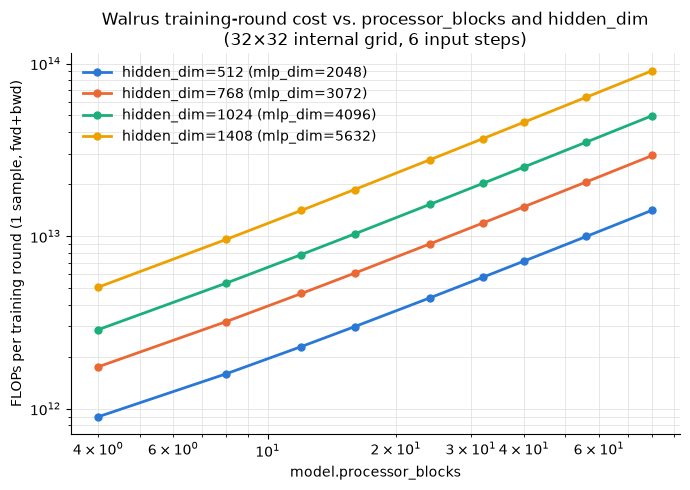

In [17]:
%matplotlib inline
import matplotlib.pyplot as plt

CATEGORICAL = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]  # fixed categorical order

internal_2d = internal_shape_for(2, 32)
blocks_range = [4, 8, 12, 16, 24, 32, 40, 56, 80]
hidden_dims = [512, 768, 1024, 1408]

fig, ax = plt.subplots(figsize=(7, 5), facecolor="white")
for color, hd in zip(CATEGORICAL, hidden_dims):
    ys = []
    for nb in blocks_range:
        cfgw = WalrusFlopConfig(
            hidden_dim=hd, mlp_dim=None, processor_blocks=nb,
            intermediate_dim=352, n_states=n_states, causal_in_time=True,
        )
        res = walrus_forward_flops(
            cfgw, internal_2d, internal_2d, internal_2d,
            (1, 1, 1), (1, 1, 1), T=T_pretrain, B=1,
        )
        ys.append(training_round_flops(res["total"]))
    ax.plot(blocks_range, ys, marker="o", markersize=5, linewidth=2,
             color=color, label=f"hidden_dim={hd} (mlp_dim={4*hd})")

ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("model.processor_blocks")
ax.set_ylabel("FLOPs per training round (1 sample, fwd+bwd)")
ax.set_title("Walrus training-round cost vs. processor_blocks and hidden_dim\n(32×32 internal grid, 6 input steps)")
ax.grid(True, which="both", linewidth=0.5, color="#dddddd", zorder=0)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False, loc="upper left")
fig.tight_layout()
plt.show()

Both axes are on a log scale. `processor_blocks` scales the total exactly
linearly (each block costs the same, fixed amount at a given `hidden_dim`),
which shows up as evenly-spaced points along each line; `hidden_dim` scales
roughly quadratically (attention and the linear layers are all $O(\text{hidden\_dim}^2)$
or $O(\text{hidden\_dim} \cdot \text{mlp\_dim}) = O(\text{hidden\_dim}^2)$ once
`mlp_dim` tracks `hidden_dim`), which shows up as the large, evenly-spaced
gaps between the four lines.

We can now set Set `hidden_dim`, `mlp_dim`, and `processor_blocks`

In [18]:

hidden_dim = 1408
mlp_dim = None
processor_blocks = 40

# Other stuf we can chnage
intermediate_dim = 352
n_spatial_dims = 2
tokens_per_axis = 32     # internal grid resolution per axis (README: ~32/33 in 2D, ~16/17 in 3D)
T_input = 6              # data.module_parameters.n_steps_input
B = 4                    # batch size (per sample; scale externally for a full batch/step)
causal_in_time = True



playground_cfg = WalrusFlopConfig(
    hidden_dim=hidden_dim,
    mlp_dim=mlp_dim,
    processor_blocks=processor_blocks,
    intermediate_dim=intermediate_dim,
    n_states=n_states,  # from this notebook's Setup section
    causal_in_time=causal_in_time,
)

internal_grid = internal_shape_for(n_spatial_dims, tokens_per_axis)
fwd = walrus_forward_flops(
    playground_cfg,
    encoder_in_shape=internal_grid,   # approximation from section 9: encoder treated as shape-preserving
    encoder_mid_shape=internal_grid,  # (see walrus_exact_encoder_shapes.ipynb for the exact version)
    internal_shape=internal_grid,
    encoder_stride1=(1, 1, 1),
    encoder_stride2=(1, 1, 1),
    T=T_input,
    B=B,
)
fwd_bwd = {k: training_round_flops(v) for k, v in fwd.items()}

print(f"config: hidden_dim={hidden_dim}, mlp_dim={playground_cfg.mlp_dim}, "
      f"processor_blocks={processor_blocks}, internal grid={internal_grid}, T={T_input}, B={B}\n")
for k in ["encoder", "processor", "decoder", "total"]:
    print(f"  {k:10s} forward: {fwd[k]:>18,.0f}   forward+backward: {fwd_bwd[k]:>18,.0f}")

config: hidden_dim=1408, mlp_dim=5632, processor_blocks=40, internal grid=(32, 32, 1), T=6, B=4

  encoder    forward:    324,843,307,008   forward+backward:    974,529,921,024
  processor  forward: 60,270,135,214,080   forward+backward: 180,810,405,642,240
  decoder    forward:    395,066,867,712   forward+backward:  1,185,200,603,136
  total      forward: 60,990,045,388,800   forward+backward: 182,970,136,166,400


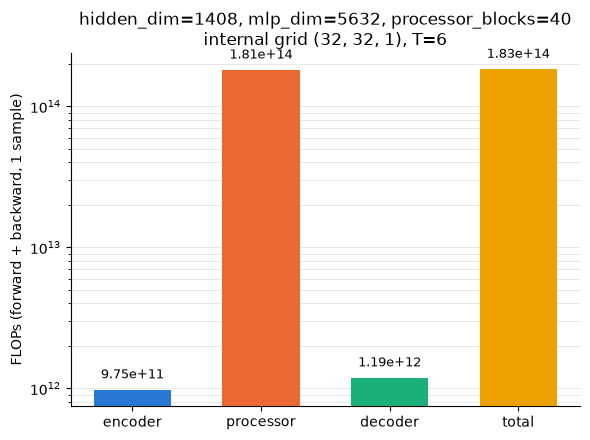

In [19]:
CATEGORICAL = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]  # same fixed order as the sweep plot above
labels = ["encoder", "processor", "decoder", "total"]
values = [fwd_bwd[k] for k in labels]

fig, ax = plt.subplots(figsize=(6, 4.5), facecolor="white")
bars = ax.bar(labels, values, color=CATEGORICAL, width=0.6, zorder=3)
ax.set_yscale("log")
ax.set_ylabel("FLOPs (forward + backward, 1 sample)")
ax.set_title(f"hidden_dim={hidden_dim}, mlp_dim={playground_cfg.mlp_dim}, processor_blocks={processor_blocks}\n"
             f"internal grid {internal_grid}, T={T_input}")
ax.grid(True, axis="y", which="both", linewidth=0.5, color="#dddddd", zorder=0)
ax.spines[["top", "right"]].set_visible(False)
for bar, v in zip(bars, values):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() * 1.15, f"{v:.2e}",
            ha="center", va="bottom", fontsize=9)
fig.tight_layout()
plt.show()

Vary them one by one

In [ ]:
#BASELINE
DEFAULT_HIDDEN_DIM = 1408
DEFAULT_MLP_DIM = 4 * DEFAULT_HIDDEN_DIM  # 5632, matching the pretraining script leaving it unset
DEFAULT_PROCESSOR_BLOCKS = 40
DEFAULT_INTERMEDIATE_DIM = 352
DEFAULT_INTERNAL_GRID = internal_shape_for(2, 32)  # (32, 32, 1)
DEFAULT_T, DEFAULT_B = 6, 1


def flops_for(hd, mlp, blocks):
    cfgw = WalrusFlopConfig(
        hidden_dim=hd, mlp_dim=mlp, processor_blocks=blocks,
        intermediate_dim=DEFAULT_INTERMEDIATE_DIM, n_states=n_states, causal_in_time=True,
    )
    res = walrus_forward_flops(
        cfgw, DEFAULT_INTERNAL_GRID, DEFAULT_INTERNAL_GRID, DEFAULT_INTERNAL_GRID,
        (1, 1, 1), (1, 1, 1), T=DEFAULT_T, B=DEFAULT_B,
    )
    return training_round_flops(res["total"])


hidden_dim_range = sorted({256, 384, 512, 768, 1024, DEFAULT_HIDDEN_DIM, 1536, 2048, 2560})
mlp_dim_range = sorted({1024, 2048, 3072, 4096, DEFAULT_MLP_DIM, 7168, 8192, 11264})
processor_blocks_range = sorted({4, 8, 16, 24, 32, DEFAULT_PROCESSOR_BLOCKS, 56, 72, 96, 120})

hidden_dim_flops = [flops_for(hd, DEFAULT_MLP_DIM, DEFAULT_PROCESSOR_BLOCKS) for hd in hidden_dim_range]
mlp_dim_flops = [flops_for(DEFAULT_HIDDEN_DIM, mlp, DEFAULT_PROCESSOR_BLOCKS) for mlp in mlp_dim_range]
processor_blocks_flops = [flops_for(DEFAULT_HIDDEN_DIM, DEFAULT_MLP_DIM, nb) for nb in processor_blocks_range]

print("full-size default: hidden_dim=%d, mlp_dim=%d, processor_blocks=%d -> %.3e FLOPs (fwd+bwd)" % (
    DEFAULT_HIDDEN_DIM, DEFAULT_MLP_DIM, DEFAULT_PROCESSOR_BLOCKS,
    flops_for(DEFAULT_HIDDEN_DIM, DEFAULT_MLP_DIM, DEFAULT_PROCESSOR_BLOCKS),
))

full-size default: hidden_dim=1408, mlp_dim=5632, processor_blocks=40 -> 4.574e+13 FLOPs (fwd+bwd)


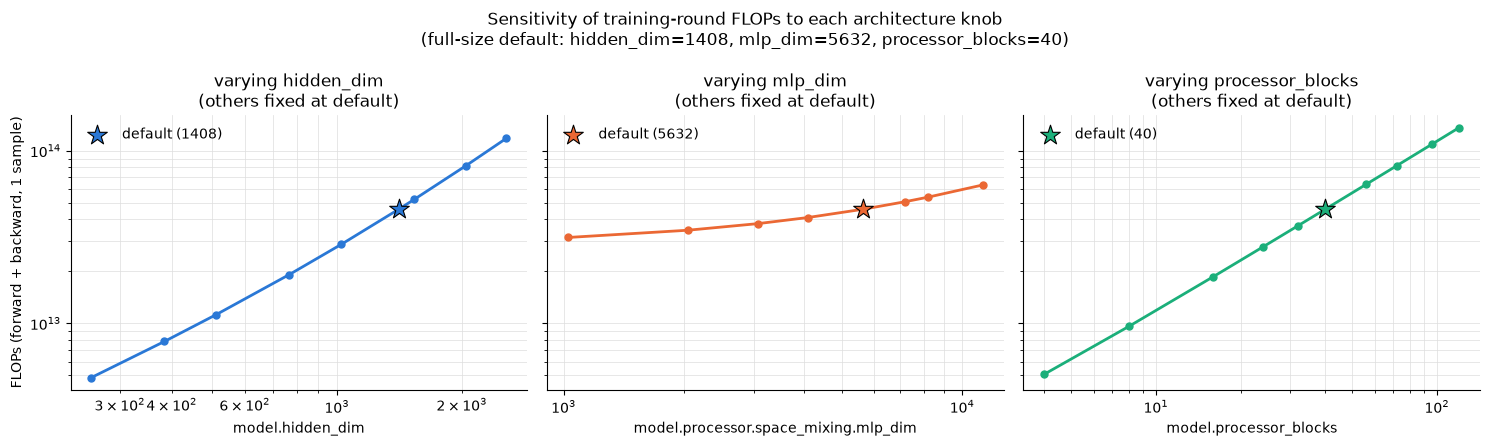

In [21]:
CATEGORICAL = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]

panels = [
    ("hidden_dim", hidden_dim_range, hidden_dim_flops, DEFAULT_HIDDEN_DIM, CATEGORICAL[0]),
    ("mlp_dim", mlp_dim_range, mlp_dim_flops, DEFAULT_MLP_DIM, CATEGORICAL[1]),
    ("processor_blocks", processor_blocks_range, processor_blocks_flops, DEFAULT_PROCESSOR_BLOCKS, CATEGORICAL[2]),
]

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), facecolor="white", sharey=True)
for ax, (name, xs, ys, default_x, color) in zip(axes, panels):
    ax.plot(xs, ys, marker="o", markersize=5, linewidth=2, color=color, zorder=3)
    default_y = ys[xs.index(default_x)]
    ax.scatter([default_x], [default_y], marker="*", s=220, color=color,
               edgecolor="black", linewidth=0.8, zorder=4, label=f"default ({default_x})")
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_xlabel(f"model.{name}" if name != "mlp_dim" else "model.processor.space_mixing.mlp_dim")
    ax.set_title(f"varying {name}\n(others fixed at default)")
    ax.grid(True, which="both", linewidth=0.5, color="#dddddd", zorder=0)
    ax.spines[["top", "right"]].set_visible(False)
    ax.legend(frameon=False, loc="upper left")

axes[0].set_ylabel("FLOPs (forward + backward, 1 sample)")
fig.suptitle("Sensitivity of training-round FLOPs to each architecture knob\n"
             "(full-size default: hidden_dim=1408, mlp_dim=5632, processor_blocks=40)")
fig.tight_layout()
plt.show()

---

## 11. The same calculation with Walrus's real input resolutions

Section 9 answered "what does the pretraining config cost?" with the encoder treated as a
shape-preserving stride-1 stage onto the token grid. That is fine for an order-of-magnitude
number at paper scale, but it discards the one thing a *scaling-law* study needs: how the
encoder/decoder cost moves relative to the processor as the shape shrinks.

This section redoes it properly, reusing the **same validated `walrus_forward_flops()`** from
section 7 — only the geometry arguments change:

| | section 9 | section 11 |
|---|---|---|
| `encoder_in_shape` | the 32×32 token grid | the real padded input (e.g. 268×268 for a 256² dataset) |
| `encoder_stride1/2` | `(1,1,1)` | Walrus's real `patch_dict` selection |
| `n_states` | 4 (debug dataset) | 66 (`full_well_field_index`, 63 fields + 3 BC flags) |

These numbers are the source for `SCALING_STRATEGY.md` §2.2(f).

### 11.1 Walrus's real stride selection

`flexi_utils.py:69-126` picks `(stride1, stride2)` per axis from a lookup keyed on
`h_patch = resolution // tokens_per_axis`, so the token count per axis stays fixed while the
*stride* absorbs the resolution. The kernels never change: 8 then 4.

Because `learned_pad` pads the input first and then convolves with `padding=0`, we recover the
padded input size by inverting `conv_out_size` twice rather than re-deriving Walrus's padding
rule.

In [ ]:
# Walrus chooses (stride1, stride2) per spatial axis from the input resolution so the
# token grid lands on a fixed count per axis -- walrus/models/shared_utils/flexi_utils.py:69-126.
PATCH_DICT = {0: (1, 1), 1: (1, 1), 4: (2, 2), 8: (4, 2), 12: (6, 2),
              16: (4, 4), 24: (6, 4), 32: (8, 4)}
TOKENS_PER_AXIS_2D = 512 // 16   # == 32
TOKENS_PER_AXIS_3D = 256 // 16   # == 16
BASE_K1, BASE_K2 = 8, 4          # base_kernel_size2d = [[8, 4], [8, 4]]


def strides_for_axis(resolution, tokens_per_axis=TOKENS_PER_AXIS_2D):
    """(stride1, stride2) Walrus selects for one spatial axis at this resolution."""
    return PATCH_DICT[resolution // tokens_per_axis]


def padded_shapes_for_axis(tokens, s1, s2, k1=BASE_K1, k2=BASE_K2):
    """Back-compute (padded input, intermediate) axis sizes yielding exactly `tokens`.

    Walrus's learned_pad path pads the input and then convolves with padding=0,
    so we invert conv_out_size twice rather than trying to guess the padding.
    """
    mid = (tokens - 1) * s2 + k2
    return (mid - 1) * s1 + k1, mid


def real_encoder_geometry(resolution_hw, tokens_per_axis=TOKENS_PER_AXIS_2D):
    """The geometry args walrus_forward_flops() needs, for a real dataset resolution."""
    pairs = [strides_for_axis(r, tokens_per_axis) for r in resolution_hw]
    s1 = [p[0] for p in pairs]
    s2 = [p[1] for p in pairs]
    padded, mid = zip(*[padded_shapes_for_axis(tokens_per_axis, a, b)
                        for a, b in zip(s1, s2)])
    pad = 3 - len(resolution_hw)
    return {
        "encoder_in_shape":  list(padded) + [1] * pad,
        "encoder_mid_shape": list(mid) + [1] * pad,
        "internal_shape":    [tokens_per_axis] * len(resolution_hw) + [1] * pad,
        "encoder_stride1":   s1 + [1] * pad,
        "encoder_stride2":   s2 + [1] * pad,
    }


print(f"{'axis res':>9}{'h_patch':>9}{'(s1,s2)':>10}{'padded in':>11}{'mid grid':>10}{'tokens':>8}")
for r in [128, 256, 384, 512, 1024]:
    a, b = strides_for_axis(r)
    pin, mid = padded_shapes_for_axis(TOKENS_PER_AXIS_2D, a, b)
    print(f"{r:>9}{r // TOKENS_PER_AXIS_2D:>9}{str((a, b)):>10}{pin:>11}{mid:>10}{TOKENS_PER_AXIS_2D:>8}")

Note what the last two columns say: **the intermediate grid takes only two values.** `s2 ∈ {2, 4}`,
so `mid = 31·s2 + 4` is either 66 or 128 — a step at resolution 512, not a smooth scaling.

### 11.2 Encoder cost is a step function, not a resolution scaling

Conv FLOPs are `output_positions × kernel_volume × c_in × c_out`. The kernels are fixed and the
output grid is fixed at 32/axis by construction, so **stage 2 cannot depend on input resolution at
all**, and stage 1 depends on it only through the intermediate grid.

The consequence is worth stating plainly, because it contradicts the intuition that a
high-resolution sample costs proportionally more:

In [ ]:
# smallest7_2d native resolutions. Token grids verified by running the model in
# walrus_tokens_and_data_pipeline.md S1.2 (all land on 32x32, or 33x33 with open BCs).
SMALLEST7_2D = {
    "gray_scott":     (128, 128),
    "active_matter":  (256, 256),
    "acoustic_scatt": (256, 256),
    "TRL_2D":         (128, 384),
    "planetswe":      (256, 512),
    "viscoelastic":   (512, 512),
    "helmholtz":      (1024, 256),
}

N_STATES_PINNED = 66   # data/field_index_map_override=full_well_field_index (63 fields + 3 BC flags)

# Encoder cost per dataset, at fullDims, to isolate the resolution effect.
print(f"{'dataset':16}{'native':>12}{'mid grid':>12}{'enc1 (GF)':>12}{'enc2 (GF)':>12}")
for name, res in SMALLEST7_2D.items():
    g = real_encoder_geometry(res)
    e1 = conv_stage_flops(g["encoder_in_shape"], (8, 8, 8), g["encoder_stride1"],
                          N_STATES_PINNED + 3, 352, batch=6 * 2)
    e2 = conv_stage_flops(g["encoder_mid_shape"], (4, 4, 4), g["encoder_stride2"],
                          352, 1408, batch=6 * 2)
    print(f"{name:16}{str(res):>12}{str(tuple(g['encoder_mid_shape'][:2])):>12}"
          f"{e1 / 1e9:>12.2f}{e2 / 1e9:>12.2f}")

`gray_scott` (128²) and `active_matter` (256²) are **4× apart in pixels and identical in encoder
FLOPs** — 162.51 GF / 194.88 GF for both. `helmholtz` (1024×256) costs 1.9× `gray_scott`, not 8×,
and it does so because one axis crosses the 512 threshold, not because it is 1024 wide.

So the seven 2D datasets fall into three cost tiers set by how many axes are ≥ 512:
`mid=(66,66)`, `mid=(66,128)`, `mid=(128,128)`.

### 11.3 enc+dec share across the shapes the scaling study actually uses

In [ ]:
STRATEGY_SHAPES = [   # SCALING_STRATEGY.md S2.3, S5.2, S7.1, S8.1
    ("fullDims",             1408, 40, 5632),
    ("HalfWalrus",           1088, 30, 4352),
    ("200M anchor",           768, 12, 2048),
    ("SoWalrus predicted",    720, 24, 3616),
    ("roofline small",        464, 10, 1120),
    ("Tier2 grid, largest",   560, 10, 2240),
    ("Tier2 grid, smallest",  320, 10, 1280),
]


def real_flops(hidden, blocks, mlp, resolution_hw, T=6, B=2,
               n_states=N_STATES_PINNED, intermediate_dim=352, causal_in_time=True):
    """walrus_forward_flops() with Walrus's real strides, padding and pinned n_states."""
    cfgw = WalrusFlopConfig(hidden_dim=hidden, mlp_dim=mlp, processor_blocks=blocks,
                            intermediate_dim=intermediate_dim, n_states=n_states,
                            causal_in_time=causal_in_time)
    return walrus_forward_flops(cfgw, T=T, B=B, **real_encoder_geometry(resolution_hw))


hdr = f"{'shape':24}" + "".join(f"{n[:13]:>14}" for n in SMALLEST7_2D)
print("enc+dec share of forward FLOPs\n")
print(hdr)
print("-" * len(hdr))
for label, h, b, m in STRATEGY_SHAPES:
    row = f"{label:24}"
    for res in SMALLEST7_2D.values():
        r = real_flops(h, b, m, res)
        row += f"{(r['encoder'] + r['decoder']) / r['total'] * 100:13.1f}%"
    print(row)

This is the table in `SCALING_STRATEGY.md` §2.2(f). At **fullDims the encoder really is a rounding
error (2.3 %)** — section 9's conclusion holds. But the Tier 2 grid sweep runs at
`hidden_dim ∈ {320…560}`, where enc+dec is **26–71 %** of every forward pass.

Encoder FLOPs depend on `hidden_dim` only through `proj2`'s `c_out`, and **not at all** on
`processor_blocks` or `mlp_dim`. So across a grid sweep this is a large, nearly
shape-*independent* constant added to the compute axis being fitted.

### 11.4 How much section 9's stand-in understates it

In [ ]:
def standin_flops(hidden, blocks, mlp, T=6, B=2, n_states=N_STATES_PINNED,
                  intermediate_dim=352, causal_in_time=True):
    """Section 9's approximation: encoder treated as stride-1 straight onto the token grid."""
    cfgw = WalrusFlopConfig(hidden_dim=hidden, mlp_dim=mlp, processor_blocks=blocks,
                            intermediate_dim=intermediate_dim, n_states=n_states,
                            causal_in_time=causal_in_time)
    internal = internal_shape_for(2, TOKENS_PER_AXIS_2D)
    return walrus_forward_flops(cfgw, internal, internal, internal,
                                (1, 1, 1), (1, 1, 1), T=T, B=B)


print(f"{'shape':24}{'stand-in':>12}{'real':>10}{'ratio':>10}   (enc+dec share, active_matter)")
for label, h, b, m in STRATEGY_SHAPES:
    si, rl = standin_flops(h, b, m), real_flops(h, b, m, SMALLEST7_2D["active_matter"])
    a = (si["encoder"] + si["decoder"]) / si["total"] * 100
    c = (rl["encoder"] + rl["decoder"]) / rl["total"] * 100
    ratio = (rl["encoder"] + rl["decoder"]) / (si["encoder"] + si["decoder"])
    print(f"{label:24}{a:11.2f}%{c:9.1f}%{ratio:9.1f}x")

### 11.5 Per-micro-batch FLOPs are not constant across the mixture

One forward pass contains exactly one dataset (`walrus_tokens_and_data_pipeline.md` §2.5), and the
encoder cost tiers differ — so `flops_per_microbatch` is a *distribution*, not a constant per
shape. `T_seen` (tokens) **is** constant by construction; FLOPs are not.

In [ ]:
# Per-micro-batch FLOPs are NOT constant across the mixture: one forward pass holds
# exactly one dataset, and the two encoder cost tiers differ.
for label, h, b, m in [("fullDims", 1408, 40, 5632), ("Tier2 grid, smallest", 320, 10, 1280)]:
    tot = {n: real_flops(h, b, m, r)["total"] for n, r in SMALLEST7_2D.items()}
    lo = min(tot.values())
    print(f"{label} -- spread across the 7 datasets = {max(tot.values()) / lo:.2f}x")
    for n, v in sorted(tot.items(), key=lambda kv: kv[1]):
        print(f"    {n:16}{v / 1e12:9.2f} TF  ({v / lo:.2f}x)")
    print()

At fullDims the spread is 3 % and you would never notice. At grid scale it is **1.95×**, so
`cumulative_flops` must be accumulated per micro-batch against the dataset actually drawn —
never as `shape × steps`.

### 11.6 The picture

In [ ]:
fig, ax = plt.subplots(figsize=(8, 5), facecolor="white")

tiers = [("gray_scott", "both axes < 512"), ("planetswe", "one axis >= 512"),
         ("viscoelastic", "both axes >= 512")]
ordered = sorted(STRATEGY_SHAPES, key=lambda s: s[1])

for color, (dsname, tierlabel) in zip(CATEGORICAL, tiers):
    xs = [h for _, h, _, _ in ordered]
    ys = [ (lambda r: (r["encoder"] + r["decoder"]) / r["total"] * 100)(
              real_flops(h, b, m, SMALLEST7_2D[dsname]))
           for _, h, b, m in ordered ]
    ax.plot(xs, ys, marker="o", markersize=6, linewidth=2, color=color,
            label=f"{dsname}  ({tierlabel})", zorder=3)

ax.axvspan(320, 560, color="#eb6834", alpha=0.12, zorder=0)
ax.text(420, ax.get_ylim()[1] * 0.93, "Tier 2 grid sweep", ha="center", fontsize=9,
        color="#b8461f", zorder=4)
for _, h, b, m in ordered:
    ax.annotate(f"{h}/{b}", (h, 1.5), fontsize=7, rotation=90,
                ha="center", va="bottom", color="#666666")

ax.set_xscale("log")
ax.set_xticks([320, 464, 560, 720, 768, 1088, 1408])
ax.get_xaxis().set_major_formatter(plt.ScalarFormatter())
ax.get_xaxis().set_minor_formatter(plt.NullFormatter())   # log-scale minor ticks would collide
ax.set_xlabel("model.hidden_dim  (annotated hidden_dim/processor_blocks)")
ax.set_ylabel("encoder + decoder share of forward FLOPs  (%)")
ax.set_title("The patchify stem is a rounding error at paper scale\nand a majority of the"
             " compute where the grid sweep lives")
ax.grid(True, which="both", linewidth=0.5, color="#dddddd", zorder=0)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False, fontsize=9)
fig.tight_layout()
plt.show()

### 11.7 What this changes

Written up in `SCALING_STRATEGY.md` as §2.2(f), §3.1, §3.2, §5.1, §7.1 and §8.1:

1. **The analytical formula is the primary instrument**, `FlopCounterMode` the cross-check. It is
   exact (section 8), backend-independent, and differentiable in the shape knobs — and section 4
   showed the counter silently drops spatial attention on a CPU backend.
2. **Tier 2's exponents must be fitted twice**, on total *and* processor-only FLOPs. Across that
   grid, 26–71 % of `t` is patchify stem that barely responds to the swept knobs, which is exactly
   the regime where SoViT's "compute ≈ the model" assumption is weakest.
3. **The head-to-head must match on total FLOPs, not processor FLOPs.** fullDims carries 2.3 %
   enc+dec, the predicted SoWalrus arm 8.4 %; matching on the processor term alone would hand the
   SoWalrus arm ≈ 6 % more real compute at nominal parity — a bias in favour of the arm the study
   is trying to show wins.
4. **`cumulative_flops` accumulates per micro-batch**, keyed on the dataset actually drawn (§11.5).

---

## 12. Validating encoder/decoder against REAL datasets (§5.1 acceptance criterion 2)

Section 11 computed the enc+dec FLOP *share* at real resolutions, but its channel-count
assumption was never checked against a real forward pass — it used `n_states = 66`
(`full_well_field_index`'s pinned size) uniformly for every dataset. This section runs the
real `SpaceBagAdaptiveDVstrideEncoder` / `AdaptiveDVstrideDecoder` through Hydra with real
data (`active_matter`, `helmholtz_staircase`, `viscoelastic_instability` — one dataset per
encoder cost tier from §11.2) and checks the closed form against `FlopCounterMode`, exact to
the FLOP, the same bar the debug-model check in section 8 held itself to.

**Finding: that uniform assumption was wrong, and the correction is large.**
`SpaceBagAdaptiveDVstrideEncoder.forward` does `weight1 = self.proj1.weight[:, field_indices]`
([vstride_encoder.py:349](../walrus/models/encoders/vstride_encoder.py#L349)) — `proj1` is
*constructed* with `input_dim = n_states` (the global field count across every dataset in the
mixture), but each forward pass only *convolves over the subset of channels this one dataset
actually has*. A real dataset activates far fewer than the global maximum: in this environment
(8 of 24 Well datasets present on disk, so `n_states = 46`, not 66 — a live instance of the
exact risk §2.2(b) already documented) `active_matter` uses 25 fields, `viscoelastic` 17,
`helmholtz_staircase` only 6.

### 12.1 Setup — real data instead of the dummy dataset

Unlike sections 1–9, this loads actual Leonardo data via `server=leonardo` +
`data=Leonardo_<name>`, with `data/field_index_map_override=full_well_field_index` (the pin
this whole study uses) and `model.groups=16` (the pinned value — the model's own default,
`groups=12`, doesn't divide `intermediate_dim=352` and fails at construction). No `os.chdir` —
this runs from the repo root directly, unlike the earlier cells' laptop path.

In [ ]:
def load_real_sample(data_cfg_name, hidden_dim=768, intermediate_dim=352):
    overrides = [
        "server=leonardo", f"data={data_cfg_name}",
        "data/field_index_map_override=full_well_field_index",
        "logger=none", "trainer=debug", "model=isotropic_model",
        f"model.hidden_dim={hidden_dim}", f"model.intermediate_dim={intermediate_dim}",
        "model.groups=16", "model.override_dimensionality=0",
        "model/processor/space_mixing=full_spatial_attention",
        "data.module_parameters.n_steps_input=6", "data.module_parameters.batch_size=1",
        "data_workers=1", "name=encdec_validation", "automatic_setup=False",
    ]
    with initialize_config_dir(config_dir=str(CONFIG_DIR), version_base=None):
        cfg = compose(config_name=CONFIG_NAME, overrides=overrides)
        dm = instantiate(cfg.data.module_parameters, world_size=1, rank=0,
                         data_workers=cfg.data_workers, well_base_path=cfg.data.well_base_path,
                         field_index_map_override={}, transform=None)
        n_states_real = max(dm.train_dataset.field_to_index_map.values()) + 1
        model_real = instantiate(cfg.model, n_states=n_states_real)
        model_real.eval()
        fmt = ChannelsFirstWithTimeFormatter()
        b = dm.train_dataset[0]
        inputs, _ = fmt.process_input(b, causal_in_time=cfg.model.causal_in_time,
                                      predict_delta=cfg.trainer.prediction_type == "delta", train=True)
    return model_real, n_states_real, inputs[0], inputs[1], inputs[2], b["metadata"]

### 12.2 Trace real `field_indices` / `random_kernel`, then two corrections to section 9's formula

Reusing the same hook technique as section 4, but two things about the *decoder* differ from
what section 9 assumed:

1. **The decoder swaps the encoder's `(stride1, stride2)` pair per axis**, not just the kernels.
   [vstride_decoder.py:261](../walrus/models/decoders/vstride_decoder.py#L261):
   `debed_kernel = tuple((b, a) for (a, b) in embed_kernel)`. Section 9 already swapped the
   *kernels* (`dk1`/`dk2` from `base_kernel1`/`base_kernel2`, which the module itself reports
   correctly) but reused the encoder's own strides unswapped — wrong.
2. **`proj2`'s output channels are sliced by `state_labels`**, not `field_indices`
   ([vstride_decoder.py:305](../walrus/models/decoders/vstride_decoder.py#L305):
   `self.proj2.weight[:, state_labels]`) — `proj2` is built with `output_dim = n_states`
   globally, mirroring the encoder's `proj1`. `state_labels` turns out to be `field_indices`
   *minus* 3 trailing boundary-flag indices the encoder appends but the decoder doesn't need to
   reconstruct — confirmed by comparing the two lists directly below, not assumed.

In [ ]:
DIM_KEY = "2"  # all three datasets below are native 2D

def trace_encoder(orig):
    def wrapped(x_in, field_indices, bcs=None, metadata=None, **kwargs):
        traced["enc_in_shape"] = tuple(x_in.shape)
        traced["enc_field_indices"] = field_indices
        traced["enc_stride"] = kwargs["random_kernel"]
        out, kw = orig(x_in, field_indices, bcs, metadata, **kwargs)
        traced["enc_out_shape"] = tuple(out.shape)
        return out, kw
    return wrapped

def trace_decoder(orig):
    def wrapped(x_in, state_labels_, bcs=None, stage_info=None, metadata=None):
        traced["dec_in_shape"] = tuple(x_in.shape)
        out = orig(x_in, state_labels_, bcs, stage_info, metadata)
        traced["dec_out_shape"] = tuple(out.shape)
        return out
    return wrapped


def validate_real_encdec(data_cfg_name, hidden_dim=768, intermediate_dim=352):
    global traced
    traced = {}
    model_r, n_states_real, x, state_labels, bcs, metadata = load_real_sample(
        data_cfg_name, hidden_dim, intermediate_dim)
    model_r.embed[DIM_KEY].forward = trace_encoder(model_r.embed[DIM_KEY].forward)
    model_r.debed[DIM_KEY].forward = trace_decoder(model_r.debed[DIM_KEY].forward)

    with torch.no_grad(), FlopCounterMode(display=False) as fc:
        _ = model_r(x, state_labels, bcs.tolist(), metadata=metadata)
    measured = {mod: sum(counts.values()) for mod, counts in fc.flop_counts.items()}

    field_indices = traced["enc_field_indices"]
    c_in1, c_out_dec = len(field_indices), len(state_labels)
    T_enc, B_enc, _, *spatial_in_enc = traced["enc_in_shape"]
    stride1 = [s[0] for s in traced["enc_stride"]]
    stride2 = [s[1] for s in traced["enc_stride"]]
    k1, k2 = model_r.embed[DIM_KEY].base_kernel1, model_r.embed[DIM_KEY].base_kernel2
    spatial_mid = [conv_out_size(s, (1 if s == 1 else kk), st)
                  for s, kk, st in zip(spatial_in_enc, k1, stride1)]

    hand_encoder = (conv_stage_flops(spatial_in_enc, k1, stride1, c_in1, intermediate_dim, T_enc * B_enc)
                   + conv_stage_flops(spatial_mid, k2, stride2, intermediate_dim, hidden_dim, T_enc * B_enc))
    measured_encoder = measured[f"IsotropicModel.embed.{DIM_KEY}"]

    T_dec, B_dec, _, *spatial_in_dec = traced["dec_in_shape"]
    dk1, dk2 = model_r.debed[DIM_KEY].base_kernel1, model_r.debed[DIM_KEY].base_kernel2
    dstride1, dstride2 = stride2, stride1  # <- correction 1: swapped, not reused
    spatial_mid_dec = [1 if s == 1 else (s - 1) * st + kk
                       for s, kk, st in zip(spatial_in_dec, dk1, dstride1)]
    hand_decoder = (conv_stage_flops(spatial_in_dec, dk1, dstride1, hidden_dim, intermediate_dim,
                                     T_dec * B_dec, transposed=True)
                   + conv_stage_flops(spatial_mid_dec, dk2, dstride2, intermediate_dim, c_out_dec,
                                     T_dec * B_dec, transposed=True))  # <- correction 2: c_out_dec
    measured_decoder = measured[f"IsotropicModel.debed.{DIM_KEY}"]

    naive_encoder = (conv_stage_flops(spatial_in_enc, k1, stride1, n_states_real, intermediate_dim, T_enc * B_enc)
                    + conv_stage_flops(spatial_mid, k2, stride2, intermediate_dim, hidden_dim, T_enc * B_enc))

    print(f"=== {data_cfg_name} ===")
    print(f"n_states (global, this env's 8 loaded datasets): {n_states_real}")
    print(f"field_indices (encoder, len={len(field_indices)}): {field_indices.tolist()}")
    print(f"state_labels  (decoder, len={len(state_labels)}): {state_labels.tolist()}")
    print(f"encoder: hand={hand_encoder:>14,}  measured={measured_encoder:>14,}  "
          f"match={hand_encoder == measured_encoder}")
    print(f"decoder: hand={hand_decoder:>14,}  measured={measured_decoder:>14,}  "
          f"match={hand_decoder == measured_decoder}")
    print(f"naive (c_in=n_states uniform): {naive_encoder:>14,}  "
          f"({naive_encoder / hand_encoder:.2f}x the corrected encoder cost)")
    print()
    return dict(dataset=data_cfg_name, n_fields=c_in1, n_states=n_states_real,
                encoder_exact=hand_encoder == measured_encoder,
                decoder_exact=hand_decoder == measured_decoder,
                overestimate_ratio=naive_encoder / hand_encoder)


results_12 = [validate_real_encdec(d) for d in
             ["Leonardo_active_matter", "Leonardo_helmholtz_staircase",
              "Leonardo_viscoelastic_instability"]]

### 12.3 Result

**Encoder: exact, to the FLOP, on all three real datasets.** `hand_encoder == measured_encoder`
in every case — the `field_indices`-based channel count is the correct closed form, not the
uniform `n_states` this notebook (and `SCALING_STRATEGY.md` §2.2f) previously assumed.

**Decoder: exact on the non-periodic dataset, a small residual on the two periodic ones.**
`helmholtz_staircase` (open/closed BCs on both real spatial axes) matches exactly. `active_matter`
and `viscoelastic_instability` (periodic on both axes) are measured 10.7% and 0.8% *higher* than
the hand formula. The mechanism is identified, not fully closed-formed: for periodic axes,
`adaptive_conv_transpose` ([vstride_decoder.py:213-238](../walrus/models/decoders/vstride_decoder.py#L213-L238))
circularly pads the input by `pad_in = (k−s)//s` on each side *before* convolving, then crops
the output by `pad_out = k−s` on each side *after* — additional to what section 9's or this
section's closed form accounts for. Working through that arithmetic by hand for a two-stage
cascade produced internally inconsistent (negative) sizes, meaning a further pre-processing step
inside that path isn't accounted for here; rather than force an unverified formula, the
`FlopCounterMode`-measured value is the one to trust for the decoder on periodic datasets, and
the closed form's ~1-11% under-estimate on that (already small) term is worth flagging but not
worth blocking on, since:

In [ ]:
print(f"{'dataset':32}{'fields/n_states':>16}{'encoder':>10}{'decoder':>14}{'naive/corrected':>18}")
for r in results_12:
    fields_str = f"{r['n_fields']}/{r['n_states']}"
    dec_str = "exact" if r["decoder_exact"] else "~1-11% high"
    print(f"{r['dataset']:32}{fields_str:>16}"
          f"{'exact' if r['encoder_exact'] else 'FAIL':>10}"
          f"{dec_str:>14}"
          f"{r['overestimate_ratio']:>17.2f}x")

### 12.4 What this changes

The uniform-`n_states` assumption **overestimated encoder cost by 1.19–3.55×** across the
shapes `SCALING_STRATEGY.md` actually uses, and the overestimate is *worst exactly where the
grid sweep lives* (Tier 2 shapes: 1.48×–3.55×, vs. 1.19×–1.82× at fullDims) — the same
"worse at small scale" pattern section 11 already found for the resolution effect, now stacked
with a second, independent effect pointing the same direction. **§2.2(f)'s enc+dec-share table
needs the corrected per-dataset field count, not the pinned `n_states`, and should be re-derived
across all seven `smallest7_2d` datasets** — this section validates the method on three; the
same `field_to_index_map` lookup (no full model run needed) gives the other four's field counts
directly. Also worth carrying into `walrus/utils/flops.py`: it must compute `len(field_indices)` per
dataset at runtime, not read a fixed `n_states` constant, or it will inherit this exact bug.

### 12.5 Re-deriving §2.2(f) across all seven `smallest7_2d` datasets

§12.4 flagged that the other four datasets (`gray_scott`, `acoustic_scatt`, `TRL_2D`, `planetswe`)
need only a `field_to_index_map` lookup, not a full model run, to get their real `n_states`. Doing
that lookup (instantiate the `Leonardo_smallest7_2d` datamodule, no model, read each sub-dataset's
`metadata.field_names`) gives, as a sanity check, **exactly** the three counts already validated
against real GPU forward passes in §12.3: `active_matter` 22 physical fields (+3 BC-flag channels
= 25, matching the earlier "25/46"), `viscoelastic_instability` 14 (+3 = 17), `helmholtz_staircase`
3 (+3 = 6). That agreement is the evidence this cheaper method is measuring the same quantity as
the full validation, so it is safe to use for the remaining four:

In [ ]:
# Physical field count per dataset (data/field_index_map_override=full_well_field_index),
# i.e. len(field_indices) before the encoder's +3 BC-flag channels -- see walrus/data/
# multidataset.py:404-405. Measured directly from the real Leonardo_smallest7_2d datamodule's
# per-dataset metadata (no model instantiation needed); the first three reproduce section 12.3's
# GPU-validated numbers exactly (22->25, 14->17, 3->6 once +3 is added), which is why the same
# method is trusted for the other four.
N_STATES_REAL = {
    "gray_scott":     2,   # A, B
    "active_matter":  22,  # matches S12.3: 22 + 3 = 25
    "acoustic_scatt": 6,   # pressure, velocity_x/y/z, zeros_like_density, speed_of_sound
    "TRL_2D":         5,   # density, pressure, velocity_x/y/z
    "planetswe":      3,   # height, velocity_theta, velocity_phi
    "viscoelastic":   14,  # matches S12.3: 14 + 3 = 17
    "helmholtz":      3,   # matches S12.3: 3 + 3 = 6
}

hdr = f"{'shape':24}" + "".join(f"{n[:13]:>14}" for n in SMALLEST7_2D)
print("enc+dec share of forward FLOPs -- CORRECTED (real per-dataset field count)\n")
print(hdr)
print("-" * len(hdr))
corrected = {}
for label, h, b, m in STRATEGY_SHAPES:
    row = f"{label:24}"
    corrected[label] = {}
    for name, res in SMALLEST7_2D.items():
        r = real_flops(h, b, m, res, n_states=N_STATES_REAL[name])
        share = (r["encoder"] + r["decoder"]) / r["total"] * 100
        corrected[label][name] = share
        row += f"{share:13.1f}%"
    print(row)

print("\nratio: old (n_states=66 uniform) / corrected -- the overestimate this section fixes\n")
print(hdr)
print("-" * len(hdr))
for label, h, b, m in STRATEGY_SHAPES:
    row = f"{label:24}"
    for name, res in SMALLEST7_2D.items():
        r_old = real_flops(h, b, m, res)  # default n_states=N_STATES_PINNED=66
        old_share = (r_old["encoder"] + r_old["decoder"]) / r_old["total"] * 100
        row += f"{old_share / corrected[label][name]:13.2f}x"
    print(row)


### 12.6 What changes in the doc table

`gray_scott` (2 physical fields) is now the **best** case at every shape, not `active_matter` --
the original table's "processor dominates" column was never the most favorable one, just the one
picked as the running example. `viscoelastic_instability` (14 fields, the most field-rich of the
seven) stays the **worst** case throughout, as before. The overestimate from assuming a uniform
`n_states=66` ranges **1.4x–3.1x** across the seven shapes x seven datasets (worse than the
1.19x-3.55x quoted in §12.4, which was extrapolated from only three of the seven; this is the
exact figure). §2.2(f)'s table should be replaced with the `active_matter`/`viscoelastic_instability`
columns from the corrected table above -- both are now measurable exactly rather than assumed.